# 🤖 scikit-learn Mastery — One Notebook to Rule Them All

A single, hands-on path through classical machine learning. Every section has a **Concept**,
a runnable **Demo**, and an **Exercise** with the solution right below.

**The one API to learn:** every model is an *estimator* with the same handful of methods.
```
model.fit(X, y)        # learn from training data
model.predict(X)       # make predictions
model.score(X, y)      # default metric (accuracy or R²)
transformer.transform(X)       # for preprocessing steps
transformer.fit_transform(X)   # fit + transform in one call
```
Learn this once and every one of the dozens of models below works the same way.

## Table of Contents
1. The estimator API & datasets
2. Train/test split
3. Preprocessing & scaling
4. Linear regression
5. Logistic regression (classification)
6. Classification metrics (confusion matrix, ROC/AUC)
7. K-nearest neighbors
8. Decision trees
9. Random forests & feature importance
10. Gradient boosting
11. Support vector machines
12. Cross-validation
13. Hyperparameter tuning (grid & random search)
14. Pipelines & ColumnTransformer
15. Clustering (K-Means)
16. Dimensionality reduction (PCA)
17. Model persistence
18. 🏆 Capstone — a full ML workflow

## 1. The Estimator API & Datasets

scikit-learn ships toy datasets (`load_*`) and synthetic data generators (`make_*`).
Features go in `X` (shape `[n_samples, n_features]`); targets go in `y` (shape `[n_samples]`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_iris, make_classification, make_regression, make_blobs
%matplotlib inline
print("scikit-learn:", sklearn.__version__)

iris = load_iris()
X, y = iris.data, iris.target
print("X shape:", X.shape, "| y shape:", y.shape)
print("features:", iris.feature_names)
print("classes :", iris.target_names)

# Synthetic data is great for controlled experiments
Xc, yc = make_classification(n_samples=200, n_features=5, n_informative=3,
                             n_classes=2, random_state=0)
Xr, yr = make_regression(n_samples=200, n_features=3, noise=10, random_state=0)
print("synthetic classification:", Xc.shape, "| regression:", Xr.shape)

scikit-learn: 1.9.1
X shape: (150, 4) | y shape: (150,)
features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
classes : ['setosa' 'versicolor' 'virginica']
synthetic classification: (200, 5) | regression: (200, 3)


**Exercise 1** — Generate a 3-class blob dataset with `make_blobs` (300 samples, 2 features, seed 0) and print the count of points per class.

In [2]:
# Your turn:

In [3]:
# Solution
Xb, yb = make_blobs(n_samples=300, centers=3, n_features=2, random_state=0)
vals, counts = np.unique(yb, return_counts=True)
print(dict(zip(vals.tolist(), counts.tolist())))

{0: 100, 1: 100, 2: 100}


## 2. Train/Test Split

Never evaluate on data you trained on. Hold out a test set to estimate real-world performance.
`stratify=y` keeps class proportions balanced across the split.

In [4]:
from sklearn.model_selection import train_test_split

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape)
print("train class balance:", np.bincount(y_train))
print("test  class balance:", np.bincount(y_test))

train: (112, 4) | test: (38, 4)
train class balance: [37 37 38]
test  class balance: [13 13 12]


**Exercise 2** — Split a synthetic classification set (400 samples) into 70% train / 30% test, stratified, and confirm the test set keeps the class ratio.

In [5]:
# Your turn:

In [6]:
# Solution
Xc, yc = make_classification(n_samples=400, weights=[0.7, 0.3], random_state=1)
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.3, stratify=yc, random_state=1)
print("overall ratio:", np.bincount(yc) / len(yc))
print("test ratio   :", np.bincount(yte) / len(yte))

overall ratio: [0.7025 0.2975]
test ratio   : [0.7 0.3]


## 3. Preprocessing & Scaling

Many models (SVM, KNN, logistic regression, PCA) assume features are on comparable scales.
**Fit the scaler on training data only**, then apply it to both train and test — fitting on
test data leaks information.

In [7]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

X, y = load_iris(return_X_y=True)
X_train, X_test = train_test_split(X, test_size=0.3, random_state=0)  # split X only

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on train
X_test_s = scaler.transform(X_test)         # only transform test
print("train mean ~0:", X_train_s.mean(axis=0).round(3))
print("train std  ~1:", X_train_s.std(axis=0).round(3))

# One-hot encoding for categorical features
cats = np.array([["red"], ["green"], ["blue"], ["red"]])
ohe = OneHotEncoder(sparse_output=False)
print("one-hot:\n", ohe.fit_transform(cats))
print("categories:", ohe.categories_)

train mean ~0: [ 0. -0. -0.  0.]
train std  ~1: [1. 1. 1. 1.]
one-hot:
 [[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]]
categories: [array(['blue', 'green', 'red'], dtype='<U5')]


**Exercise 3** — Scale a feature matrix to the [0, 1] range with `MinMaxScaler` and confirm each column's min is 0 and max is 1.

In [8]:
# Your turn:

In [9]:
# Solution
X, _ = load_iris(return_X_y=True)
Xs = MinMaxScaler().fit_transform(X)
print("mins:", Xs.min(axis=0))
print("maxs:", Xs.max(axis=0))

mins: [0. 0. 0. 0.]
maxs: [1. 1. 1. 1.]


## 4. Linear Regression

Predict a continuous target. Evaluate with R² (1.0 is perfect) and error metrics.

coef: 96.96 | intercept: -2.75
R²  : 0.973
RMSE: 13.24
MAE : 10.73


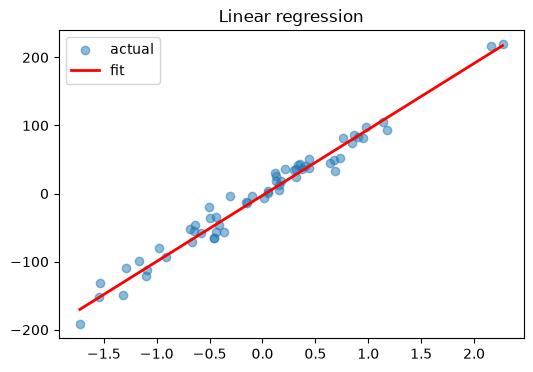

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X, y = make_regression(n_samples=200, n_features=1, noise=15, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
print(f"coef: {model.coef_[0]:.2f} | intercept: {model.intercept_:.2f}")
print(f"R²  : {r2_score(y_test, pred):.3f}")
print(f"RMSE: {mean_squared_error(y_test, pred) ** 0.5:.2f}")
print(f"MAE : {mean_absolute_error(y_test, pred):.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(X_test, y_test, alpha=0.5, label="actual")
ax.plot(np.sort(X_test, axis=0), model.predict(np.sort(X_test, axis=0)), 'r', lw=2, label="fit")
ax.legend(); ax.set_title("Linear regression")
plt.show()

**Exercise 4** — Fit a `LinearRegression` on a 3-feature regression set and report test R². Which feature has the largest absolute coefficient?

In [11]:
# Your turn:

In [12]:
# Solution
X, y = make_regression(n_samples=300, n_features=3, noise=10, random_state=2)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=2)
m = LinearRegression().fit(Xtr, ytr)
print("R²:", round(r2_score(yte, m.predict(Xte)), 3))
print("largest-|coef| feature index:", int(np.argmax(np.abs(m.coef_))))

R²: 0.989
largest-|coef| feature index: 2


## 5. Logistic Regression (Classification)

Despite the name, this is a **classifier**. It outputs class probabilities via `predict_proba`.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y = make_classification(n_samples=300, n_features=4, n_informative=3, n_redundant=0,
                           n_classes=2, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

clf = LogisticRegression(max_iter=1000).fit(X_train, y_train)
pred = clf.predict(X_test)
proba = clf.predict_proba(X_test)
print("accuracy:", round(accuracy_score(y_test, pred), 3))
print("first 3 predicted probabilities:\n", proba[:3].round(3))
print("default .score():", round(clf.score(X_test, y_test), 3))

accuracy: 0.6
first 3 predicted probabilities:
 [[0.308 0.692]
 [0.361 0.639]
 [0.104 0.896]]
default .score(): 0.6


**Exercise 5** — Train logistic regression on the iris dataset (3 classes) and report test accuracy.

In [14]:
# Your turn:

In [15]:
# Solution
X, y = load_iris(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
clf = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
print("accuracy:", round(clf.score(Xte, yte), 3))

accuracy: 1.0


## 6. Classification Metrics

Accuracy alone is misleading on imbalanced data. Use the confusion matrix, precision/recall/F1,
and the ROC curve with its AUC.

              precision    recall  f1-score   support

           0       0.90      0.88      0.89        83
           1       0.74      0.78      0.76        37

    accuracy                           0.85       120
   macro avg       0.82      0.83      0.83       120
weighted avg       0.85      0.85      0.85       120



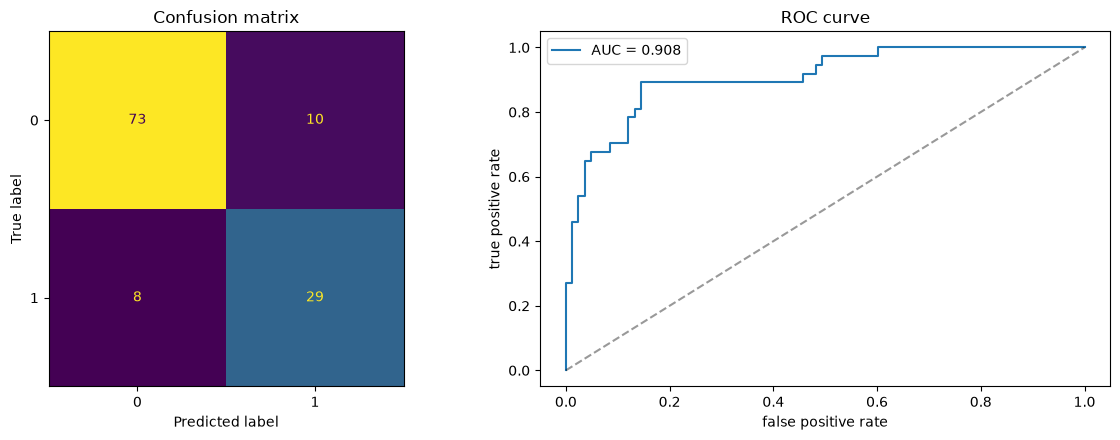

In [16]:
from sklearn.metrics import (confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)

X, y = make_classification(n_samples=400, weights=[0.7, 0.3], random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
clf = LogisticRegression(max_iter=1000).fit(X_train, y_train)
pred = clf.predict(X_test)
scores = clf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix")

fpr, tpr, _ = roc_curve(y_test, scores)
auc = roc_auc_score(y_test, scores)
axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].legend(); axes[1].set_title("ROC curve")
plt.tight_layout(); plt.show()

**Exercise 6** — For the model above, print the precision and recall for the positive class only (hint: `precision_score`, `recall_score`).

In [17]:
# Your turn:

In [18]:
# Solution
from sklearn.metrics import precision_score, recall_score
print("precision:", round(precision_score(y_test, pred), 3))
print("recall   :", round(recall_score(y_test, pred), 3))

precision: 0.744
recall   : 0.784


## 7. K-Nearest Neighbors

A simple, non-parametric classifier: a point's label is a vote of its `k` nearest neighbors.
Sensitive to feature scale, so scale first.

In [19]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

# Try several k values
for k in [1, 3, 5, 15]:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    knn.fit(X_train, y_train)
    print(f"k={k:2d} -> test accuracy {knn.score(X_test, y_test):.3f}")

k= 1 -> test accuracy 0.956
k= 3 -> test accuracy 0.978


k= 5 -> test accuracy 0.978
k=15 -> test accuracy 0.956


**Exercise 7** — On the iris data, find which k in 1..20 gives the best test accuracy (scaled KNN).

In [20]:
# Your turn:

In [21]:
# Solution
best_k, best_acc = None, 0
for k in range(1, 21):
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    acc = knn.fit(X_train, y_train).score(X_test, y_test)
    if acc > best_acc:
        best_k, best_acc = k, acc
print(f"best k={best_k} with accuracy {best_acc:.3f}")

best k=13 with accuracy 1.000


## 8. Decision Trees

A tree of if/else splits. Interpretable, needs no scaling, but overfits if grown too deep —
control with `max_depth`.

train acc: 0.962
test  acc: 0.956


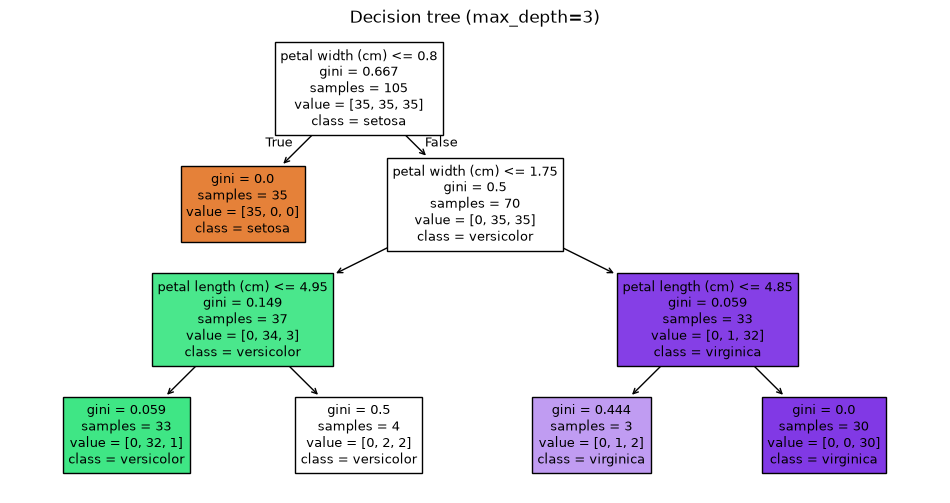

In [22]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
print("train acc:", round(tree.score(X_train, y_train), 3))
print("test  acc:", round(tree.score(X_test, y_test), 3))

fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(tree, feature_names=load_iris().feature_names,
          class_names=list(load_iris().target_names), filled=True, ax=ax, fontsize=9)
ax.set_title("Decision tree (max_depth=3)")
plt.show()

**Exercise 8** — Show overfitting: train trees of depth 1, 3, 5, and None, printing train vs test accuracy for each. Where does the gap widen?

In [23]:
# Your turn:

In [24]:
# Solution
for d in [1, 3, 5, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    print(f"depth={str(d):4} train={t.score(X_train, y_train):.3f} test={t.score(X_test, y_test):.3f}")

depth=1    train=0.667 test=0.667
depth=3    train=0.962 test=0.956
depth=5    train=1.000 test=0.978
depth=None train=1.000 test=0.978


## 9. Random Forests & Feature Importance

An ensemble of many trees on random data/feature subsets, averaged. Strong default classifier,
and it reports which features mattered.

test accuracy: 0.978


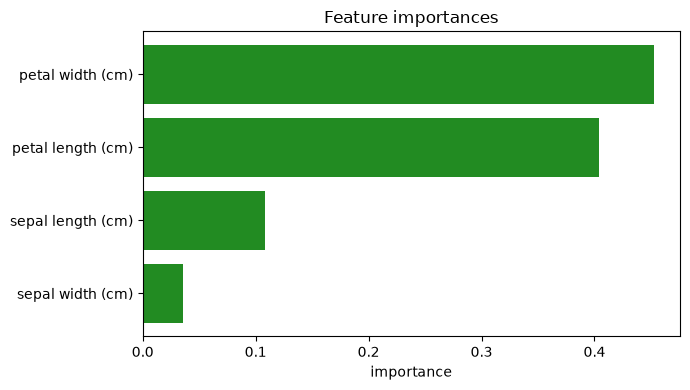

In [25]:
from sklearn.ensemble import RandomForestClassifier

X, y = load_iris(return_X_y=True)
names = load_iris().feature_names
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_train, y_train)
print("test accuracy:", round(rf.score(X_test, y_test), 3))

imp = rf.feature_importances_
order = np.argsort(imp)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([names[i] for i in order][::-1], imp[order][::-1], color='forestgreen')
ax.set_title("Feature importances"); ax.set_xlabel("importance")
plt.tight_layout(); plt.show()

**Exercise 9** — Train a random forest on a 10-feature synthetic set where only 3 are informative; print the indices of the 3 most important features.

In [26]:
# Your turn:

In [27]:
# Solution
X, y = make_classification(n_samples=500, n_features=10, n_informative=3,
                           n_redundant=0, shuffle=False, random_state=0)
rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(X, y)
top3 = np.argsort(rf.feature_importances_)[::-1][:3]
print("top 3 feature indices:", sorted(top3.tolist()), "(informative were 0,1,2)")

top 3 feature indices: [0, 1, 2] (informative were 0,1,2)


## 10. Gradient Boosting

Trees built sequentially, each correcting the previous one's errors. `HistGradientBoosting` is
scikit-learn's fast, modern implementation — often the best off-the-shelf tabular model.

In [28]:
from sklearn.ensemble import HistGradientBoostingClassifier

X, y = make_classification(n_samples=1000, n_features=20, n_informative=10, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=0)
gb.fit(X_train, y_train)
print("train acc:", round(gb.score(X_train, y_train), 3))
print("test  acc:", round(gb.score(X_test, y_test), 3))

# Compare against a single tree and a random forest
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_train, y_train)
dt = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print(f"single tree: {dt.score(X_test, y_test):.3f} | forest: {rf.score(X_test, y_test):.3f} "
      f"| boosting: {gb.score(X_test, y_test):.3f}")

train acc: 1.0
test  acc: 0.877


single tree: 0.773 | forest: 0.867 | boosting: 0.877


**Exercise 10** — Train a `HistGradientBoostingClassifier` with 50 vs 300 iterations and compare test accuracy.

In [29]:
# Your turn:

In [30]:
# Solution
for it in [50, 300]:
    g = HistGradientBoostingClassifier(max_iter=it, random_state=0).fit(X_train, y_train)
    print(f"max_iter={it}: test acc {g.score(X_test, y_test):.3f}")

max_iter=50: test acc 0.887


max_iter=300: test acc 0.890


## 11. Support Vector Machines

SVMs find the maximum-margin boundary; the `rbf` kernel handles non-linear separation.
Scale features first.

linear kernel -> test accuracy 1.000
rbf    kernel -> test accuracy 0.989


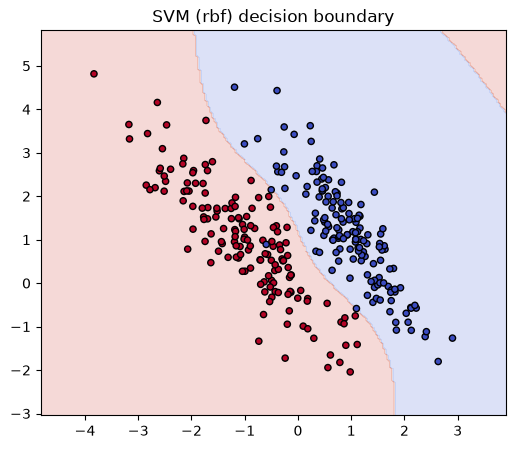

In [31]:
from sklearn.svm import SVC

X, y = make_classification(n_samples=300, n_features=2, n_informative=2, n_redundant=0,
                           n_clusters_per_class=1, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

for kernel in ["linear", "rbf"]:
    svm = make_pipeline(StandardScaler(), SVC(kernel=kernel)).fit(X_train, y_train)
    print(f"{kernel:6} kernel -> test accuracy {svm.score(X_test, y_test):.3f}")

# Visualize the rbf decision boundary
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf")).fit(X_train, y_train)
xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 200),
                     np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 200))
Z = svm.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(xx, yy, Z, alpha=0.2, cmap="coolwarm")
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=20)
ax.set_title("SVM (rbf) decision boundary")
plt.show()

**Exercise 11** — Compare SVC with `C=0.1` vs `C=10` (rbf kernel, scaled) on the data above. What happens to train vs test accuracy?

In [32]:
# Your turn:

In [33]:
# Solution
for C in [0.1, 10]:
    s = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C)).fit(X_train, y_train)
    print(f"C={C}: train {s.score(X_train, y_train):.3f} test {s.score(X_test, y_test):.3f}")

C=0.1: train 0.976 test 1.000
C=10: train 0.990 test 0.989


## 12. Cross-Validation

A single train/test split is noisy. K-fold CV rotates the test fold `k` times and averages,
giving a more reliable estimate with a spread. Use `StratifiedKFold` for classification.

In [34]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

X, y = load_iris(return_X_y=True)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
scores = cross_val_score(clf, X, y, cv=cv)
print("fold scores:", scores.round(3))
print(f"mean {scores.mean():.3f} ± {scores.std():.3f}")

fold scores: [0.967 0.967 0.967 0.967 0.933]
mean 0.960 ± 0.013


**Exercise 12** — Run 10-fold cross-validation for a random forest on the iris data and report the mean ± std accuracy.

In [35]:
# Your turn:

In [36]:
# Solution
rf = RandomForestClassifier(n_estimators=100, random_state=0)
s = cross_val_score(rf, X, y, cv=StratifiedKFold(10, shuffle=True, random_state=0))
print(f"mean {s.mean():.3f} ± {s.std():.3f}")

mean 0.940 ± 0.047


## 13. Hyperparameter Tuning

`GridSearchCV` exhaustively tries a parameter grid with cross-validation; `RandomizedSearchCV`
samples from distributions, cheaper for large spaces. Both refit the best model on all data.

In [37]:
from sklearn.model_selection import GridSearchCV

X, y = load_iris(return_X_y=True)
pipe = make_pipeline(StandardScaler(), SVC())
param_grid = {
    "svc__C": [0.1, 1, 10],
    "svc__gamma": ["scale", 0.1, 1],
    "svc__kernel": ["rbf"],
}
grid = GridSearchCV(pipe, param_grid, cv=5, n_jobs=-1)
grid.fit(X, y)
print("best params:", grid.best_params_)
print("best CV score:", round(grid.best_score_, 3))
print("you can predict directly with the refit best model:", grid.predict(X[:3]))

best params: {'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
best CV score: 0.973
you can predict directly with the refit best model: [0 0 0]


**Exercise 13** — Grid-search a random forest over `n_estimators` in [50, 200] and `max_depth` in [3, 5, None]; print the best params and score.

In [38]:
# Your turn:

In [39]:
# Solution
grid = GridSearchCV(
    RandomForestClassifier(random_state=0),
    {"n_estimators": [50, 200], "max_depth": [3, 5, None]},
    cv=5, n_jobs=-1).fit(X, y)
print("best:", grid.best_params_, "| score:", round(grid.best_score_, 3))

best: {'max_depth': 5, 'n_estimators': 50} | score: 0.96


## 14. Pipelines & ColumnTransformer

A `Pipeline` chains preprocessing + model into one estimator — so the scaler is refit inside
each CV fold, preventing leakage. `ColumnTransformer` applies different steps to different columns.

In [40]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# A mixed-type table: numeric + categorical
df = pd.DataFrame({
    "age": [25, 40, 35, 50, 23, 45],
    "income": [50, 80, 60, 120, 40, 90],
    "city": ["NY", "LA", "NY", "SF", "LA", "SF"],
    "bought": [0, 1, 0, 1, 0, 1],
})
X = df.drop(columns="bought"); y = df["bought"]

pre = ColumnTransformer([
    ("num", StandardScaler(), ["age", "income"]),
    ("cat", OneHotEncoder(), ["city"]),
])
pipe = Pipeline([("pre", pre), ("clf", LogisticRegression())])
pipe.fit(X, y)
print("pipeline steps:", [name for name, _ in pipe.steps])
print("prediction on first row:", pipe.predict(X.iloc[[0]]))
print("transformed feature count:", pipe.named_steps["pre"].transform(X).shape[1])

pipeline steps: ['pre', 'clf']
prediction on first row: [0]
transformed feature count: 5


**Exercise 14** — Build a pipeline that scales numeric columns `['age','income']`, one-hot-encodes `['city']`, and fits a random forest. Confirm it predicts on the full frame.

In [41]:
# Your turn:

In [42]:
# Solution
pre = ColumnTransformer([
    ("num", StandardScaler(), ["age", "income"]),
    ("cat", OneHotEncoder(), ["city"]),
])
pipe = Pipeline([("pre", pre), ("rf", RandomForestClassifier(random_state=0))])
pipe.fit(X, y)
print("predictions:", pipe.predict(X))

predictions: [0 1 0 1 0 1]


## 15. Clustering (K-Means)

Unsupervised: group unlabeled points into `k` clusters. The elbow method helps choose `k`.

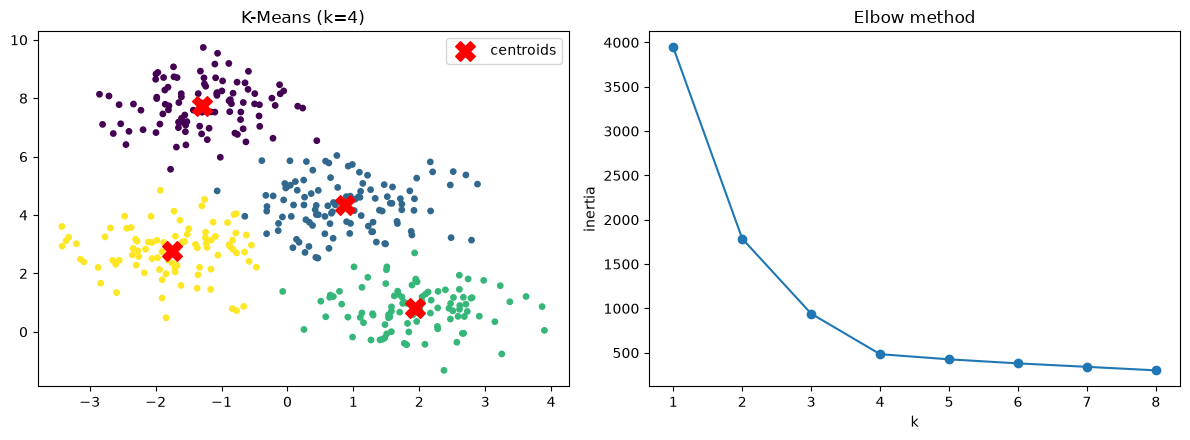

In [43]:
from sklearn.cluster import KMeans

X, y_true = make_blobs(n_samples=400, centers=4, cluster_std=0.8, random_state=0)
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="viridis", s=15)
axes[0].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
                c="red", marker="X", s=200, label="centroids")
axes[0].legend(); axes[0].set_title("K-Means (k=4)")

# Elbow: inertia vs k
ks = range(1, 9)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
axes[1].plot(list(ks), inertias, "o-")
axes[1].set_xlabel("k"); axes[1].set_ylabel("inertia"); axes[1].set_title("Elbow method")
plt.tight_layout(); plt.show()

**Exercise 15** — Cluster a 3-center blob dataset with K-Means and measure agreement with the true labels using `adjusted_rand_score`.

In [44]:
# Your turn:

In [45]:
# Solution
from sklearn.metrics import adjusted_rand_score
X, y_true = make_blobs(n_samples=300, centers=3, random_state=1)
labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X)
print("adjusted Rand index:", round(adjusted_rand_score(y_true, labels), 3))

adjusted Rand index: 0.98


## 16. Dimensionality Reduction (PCA)

PCA projects data onto the directions of greatest variance — for visualization, compression,
and denoising. Always scale first.

explained variance ratio: [0.73  0.229]
cumulative: [0.73  0.958]


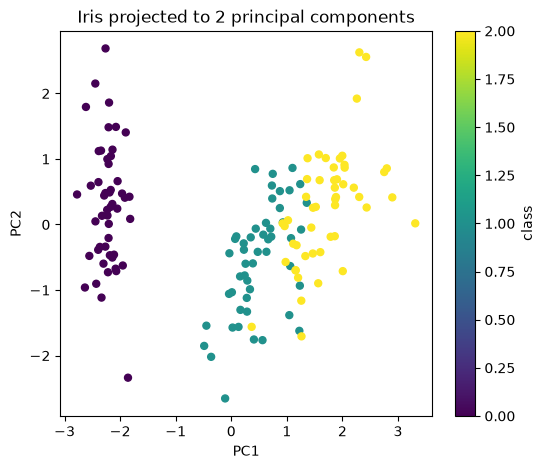

In [46]:
from sklearn.decomposition import PCA

X, y = load_iris(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2).fit(X_scaled)
X_2d = pca.transform(X_scaled)

print("explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("cumulative:", pca.explained_variance_ratio_.cumsum().round(3))

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="viridis", s=25)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("Iris projected to 2 principal components")
plt.colorbar(sc, label="class")
plt.show()

**Exercise 16** — How many principal components are needed to explain at least 95% of the variance in the (scaled) iris data?

In [47]:
# Your turn:

In [48]:
# Solution
pca = PCA().fit(StandardScaler().fit_transform(X))
cum = pca.explained_variance_ratio_.cumsum()
n = int(np.argmax(cum >= 0.95) + 1)
print("cumulative variance:", cum.round(3))
print("components for >=95%:", n)

cumulative variance: [0.73  0.958 0.995 1.   ]
components for >=95%: 2


## 17. Model Persistence

Save a trained model (or whole pipeline) with `joblib`, then load and reuse it without retraining.

In [49]:
import joblib, tempfile, os

X, y = load_iris(return_X_y=True)
pipe = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=0))
pipe.fit(X, y)

tmp = tempfile.mkdtemp()
path = os.path.join(tmp, "model.joblib")
joblib.dump(pipe, path)
print("saved:", os.path.getsize(path), "bytes")

reloaded = joblib.load(path)
print("reloaded matches original:",
      np.array_equal(pipe.predict(X), reloaded.predict(X)))

saved: 189258 bytes
reloaded matches original: True


**Exercise 17** — Train a logistic-regression pipeline, save it with joblib, reload it, and confirm predictions match on the first 10 rows.

In [50]:
# Your turn:

In [51]:
# Solution
import joblib, tempfile, os
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, y)
p = os.path.join(tempfile.mkdtemp(), "lr.joblib")
joblib.dump(pipe, p)
m2 = joblib.load(p)
print("match:", np.array_equal(pipe.predict(X[:10]), m2.predict(X[:10])))

match: True


## 18. 🏆 Capstone — A Full ML Workflow

Everything together on one problem. Try before peeking.

**Task.** On a synthetic binary-classification dataset: (1) split train/test; (2) build a
pipeline (scale → classifier); (3) grid-search hyperparameters with cross-validation;
(4) evaluate the best model on the held-out test set with a classification report, confusion
matrix, and ROC/AUC.

In [52]:
# Your turn:

best params: {'clf__learning_rate': 0.1, 'clf__max_iter': 300}
best CV AUC: 0.979

               precision    recall  f1-score   support

           0       0.95      0.96      0.95       162
           1       0.92      0.91      0.91        88

    accuracy                           0.94       250
   macro avg       0.94      0.93      0.93       250
weighted avg       0.94      0.94      0.94       250



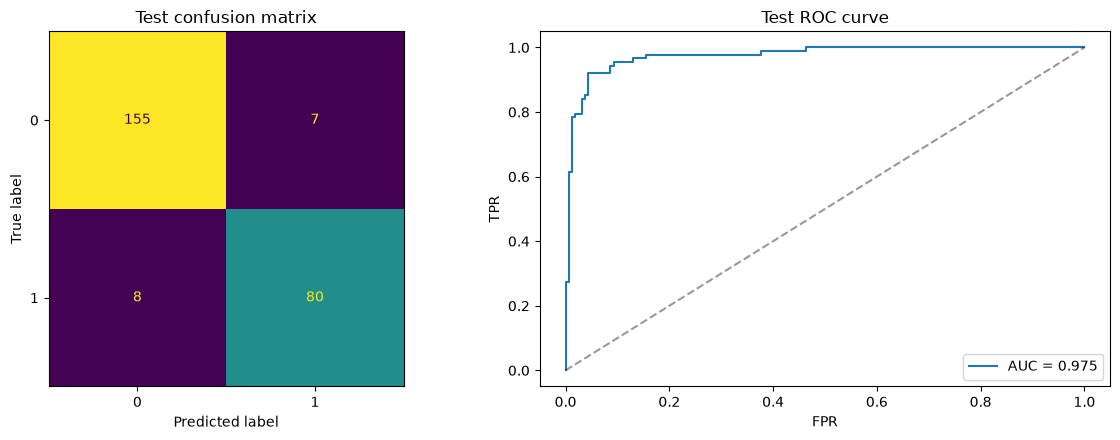

In [53]:
# Solution
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix, roc_curve, roc_auc_score

X, y = make_classification(n_samples=1000, n_features=15, n_informative=8,
                           weights=[0.65, 0.35], random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

pipe = Pipeline([("scale", StandardScaler()),
                 ("clf", HistGradientBoostingClassifier(random_state=0))])
grid = GridSearchCV(pipe,
                    {"clf__max_iter": [100, 300], "clf__learning_rate": [0.05, 0.1]},
                    cv=5, n_jobs=-1, scoring="roc_auc")
grid.fit(X_train, y_train)
print("best params:", grid.best_params_)
print("best CV AUC:", round(grid.best_score_, 3))

best = grid.best_estimator_
pred = best.predict(X_test)
scores = best.predict_proba(X_test)[:, 1]
print("\n", classification_report(y_test, pred))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Test confusion matrix")
fpr, tpr, _ = roc_curve(y_test, scores)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, scores):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4); axes[1].legend()
axes[1].set_title("Test ROC curve"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")
plt.tight_layout(); plt.show()

---
## 🎓 You Made It

If you can build a `Pipeline`, tune it with `GridSearchCV`, and read a classification report,
you have the professional ML workflow. Where to go next:

- Learn `XGBoost` / `LightGBM` — the competition-grade gradient boosters with a scikit-learn API.
- Study the bias-variance trade-off and learning curves (`sklearn.model_selection.learning_curve`).
- Move to **Hugging Face Transformers** (next notebook) for deep learning on text.

Delete the solution cells and redo the exercises in a week — spaced repetition turns practice
into mastery.